# Minería de Datos
## Análisis de factores asociados al bajo rendimiento académico

**Pregunta de negocio:** ¿Qué factores académicos, familiares y de comportamiento se asocian con el bajo rendimiento académico y pueden ayudar a identificar estudiantes que requieren seguimiento?

**Alcance de esta versión:** el repositorio UCI ofrece archivos separados para Matemáticas y Portugués. En este notebook se analiza únicamente el archivo de Matemáticas. Como no hay un identificador individual común documentado que permita confirmar que una fila de un archivo es la misma persona que una fila del otro, no se construye una llave artificial ni se cruzan perfiles. De esta manera se conserva la muestra original de Matemáticas.

**Definición operativa:** para este ejercicio se considera bajo rendimiento una calificación final `G3 < 10` en una escala de 0 a 20. Es un criterio de trabajo para el análisis y debe confirmarse con el criterio académico del curso o institución.

**Fuente del conjunto de datos:** Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T



## Preparación y carga de datos

Sube `student-mat.csv` cuando Colab abra el selector de archivos. No es necesario subir ni combinar `student-por.csv` para este análisis.

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

if "student-mat.csv" not in uploaded:
    raise FileNotFoundError(
        "Debes subir el archivo student-mat.csv para continuar."
    )

mat = pd.read_csv("student-mat.csv", sep=";")

# Se agrega el sufijo _mat para identificar claramente el origen de las columnas.
datos = mat.add_suffix("_mat").copy()

print("Dimensiones originales de Matemáticas:", mat.shape)
print("Dimensiones de la base de trabajo:", datos.shape)
display(datos.head())

Saving student-mat.csv to student-mat.csv
Saving student-por.csv to student-por.csv
Dimensiones originales de Matemáticas: (395, 33)
Dimensiones de la base de trabajo: (395, 33)


,school_mat,sex_mat,age_mat,address_mat,famsize_mat,Pstatus_mat,Medu_mat,Fedu_mat,Mjob_mat,Fjob_mat,...,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


 Calidad de datos

Se revisan tipos de datos, valores faltantes, registros duplicados y valores atípicos. Las columnas numéricas se convierten explícitamente a formato numérico cuando corresponde. No se eliminan registros automáticamente: cualquier corrección debe basarse en evidencia.

In [3]:
# Variables numéricas del conjunto de Matemáticas
variables_numericas = [
    "age_mat", "Medu_mat", "Fedu_mat", "traveltime_mat",
    "studytime_mat", "failures_mat", "famrel_mat", "freetime_mat",
    "goout_mat", "Dalc_mat", "Walc_mat", "health_mat",
    "absences_mat", "G1_mat", "G2_mat", "G3_mat"
]

columnas_convertidas = []
for columna in variables_numericas:
    tipo_anterior = datos[columna].dtype
    datos[columna] = pd.to_numeric(datos[columna], errors="coerce")
    tipo_actual = datos[columna].dtype
    if tipo_actual != tipo_anterior:
        columnas_convertidas.append((columna, str(tipo_anterior), str(tipo_actual)))

print("Columnas cuyo tipo cambió:")
if columnas_convertidas:
    display(pd.DataFrame(
        columnas_convertidas,
        columns=["Columna", "Tipo anterior", "Tipo actual"]
    ))
else:
    print("No fue necesario cambiar tipos: las variables numéricas ya estaban en formato numérico.")

print("\nINFORMACIÓN GENERAL")
datos.info()

print("\nTIPOS DE DATOS")
display(datos.dtypes.to_frame("tipo"))

print("\nVALORES NULOS POR COLUMNA")
display(datos.isnull().sum().to_frame("valores_nulos"))
print("Total de valores nulos:", int(datos.isnull().sum().sum()))

print("\nREGISTROS DUPLICADOS COMPLETOS:", int(datos.duplicated().sum()))

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(datos[variables_numericas].describe())

Columnas cuyo tipo cambió:
No fue necesario cambiar tipos: las variables numéricas ya estaban en formato numérico.

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   school_mat      395 non-null    object
 1   sex_mat         395 non-null    object
 2   age_mat         395 non-null    int64 
 3   address_mat     395 non-null    object
 4   famsize_mat     395 non-null    object
 5   Pstatus_mat     395 non-null    object
 6   Medu_mat        395 non-null    int64 
 7   Fedu_mat        395 non-null    int64 
 8   Mjob_mat        395 non-null    object
 9   Fjob_mat        395 non-null    object
 10  reason_mat      395 non-null    object
 11  guardian_mat    395 non-null    object
 12  traveltime_mat  395 non-null    int64 
 13  studytime_mat   395 non-null    int64 
 14  failures_mat    395 non-null    int64 
 15  school

,tipo
school_mat,object
sex_mat,object
age_mat,int64
address_mat,object
famsize_mat,object
Pstatus_mat,object
Medu_mat,int64
Fedu_mat,int64
Mjob_mat,object
Fjob_mat,object



VALORES NULOS POR COLUMNA


,valores_nulos
school_mat,0
sex_mat,0
age_mat,0
address_mat,0
famsize_mat,0
Pstatus_mat,0
Medu_mat,0
Fedu_mat,0
Mjob_mat,0
Fjob_mat,0


Total de valores nulos: 0

REGISTROS DUPLICADOS COMPLETOS: 0

ESTADÍSTICAS DESCRIPTIVAS


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,Walc_mat,health_mat,absences_mat,G1_mat,G2_mat,G3_mat
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


### Validación de rangos y consistencias

La documentación del conjunto describe las notas `G1`, `G2` y `G3` en el intervalo de 0 a 20, y las ausencias en el intervalo de 0 a 93. Se comprueban esos rangos antes de decidir si hay errores. Los registros fuera de rango se deben revisar; este notebook no los corrige ni elimina sin inspección.

In [4]:
# Revisar notas fuera del rango documentado (0 a 20)
columnas_notas = ["G1_mat", "G2_mat", "G3_mat"]
mascara_notas_invalidas = datos[columnas_notas].lt(0).any(axis=1) | datos[columnas_notas].gt(20).any(axis=1)
notas_fuera_rango = datos.loc[mascara_notas_invalidas, columnas_notas]

# Revisar ausencias fuera del rango documentado (0 a 93)
mascara_ausencias_invalidas = (datos["absences_mat"] < 0) | (datos["absences_mat"] > 93)
ausencias_fuera_rango = datos.loc[mascara_ausencias_invalidas, ["absences_mat"]]

print("Registros con alguna nota fuera de 0–20:", len(notas_fuera_rango))
display(notas_fuera_rango)
print("Registros con ausencias fuera de 0–93:", len(ausencias_fuera_rango))
display(ausencias_fuera_rango)

print("\nDecisión: si estas tablas están vacías, no se detectaron valores fuera de los rangos documentados. Si aparece algún registro, se revisa contra la fuente antes de corregirlo o excluirlo.")

Registros con alguna nota fuera de 0–20: 0


,G1_mat,G2_mat,G3_mat


Registros con ausencias fuera de 0–93: 0


,absences_mat



Decisión: si estas tablas están vacías, no se detectaron valores fuera de los rangos documentados. Si aparece algún registro, se revisa contra la fuente antes de corregirlo o excluirlo.


### Identificación y tratamiento de valores atípicos

Se utiliza el rango intercuartílico (IQR) para identificar observaciones extremas. Un valor atípico estadístico no es necesariamente un error, por lo que no se eliminan registros automáticamente.

**Resultado de la ejecución guardada con los 395 registros de Matemáticas:**

- **Ausencias (`absences_mat`):** el IQR identificó 15 observaciones, con valores entre 21 y 75 ausencias. Los límites calculados fueron -12 y 20. Estos registros están dentro del rango documentado de la variable (0–93), por lo que se conservan y se marcan con `marca_atipico_ausencias`. La decisión es no eliminarlos porque pueden representar ausencias reales.
- **Calificación final (`G3_mat`):** el IQR no identificó observaciones atípicas (0 casos). Los límites calculados fueron -1 y 23; las notas observadas están dentro del rango válido de 0 a 20. Por tanto, no hay registros de G3 que requieran tratamiento por IQR.

La celda siguiente calcula nuevamente los límites, muestra los registros identificados y crea las columnas booleanas de marcado. Si se vuelve a ejecutar con un archivo diferente, deben utilizarse los nuevos resultados impresos.

In [5]:
def detectar_atipicos(data, columna):
    q1 = data[columna].quantile(0.25)
    q3 = data[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara = (data[columna] < limite_inferior) | (data[columna] > limite_superior)
    atipicos = data.loc[mascara, [columna]].copy()
    atipicos.insert(0, "indice_original", atipicos.index)

    print(f"\nVariable: {columna}")
    print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"Límite inferior: {limite_inferior:.2f}")
    print(f"Límite superior: {limite_superior:.2f}")
    print(f"Cantidad de valores atípicos: {len(atipicos)}")
    display(atipicos)
    return atipicos

atipicos_ausencias = detectar_atipicos(datos, "absences_mat")
atipicos_calificaciones = detectar_atipicos(datos, "G3_mat")

# Se marcan en la base sin borrar ni modificar el valor original.
datos["marca_atipico_ausencias"] = datos.index.isin(atipicos_ausencias["indice_original"])
datos["marca_atipico_G3"] = datos.index.isin(atipicos_calificaciones["indice_original"])

print("\nRegistros marcados por ausencias:", int(datos["marca_atipico_ausencias"].sum()))
print("Registros marcados por G3:", int(datos["marca_atipico_G3"].sum()))


Variable: absences_mat
Q1: 0.00 | Q3: 8.00 | IQR: 8.00
Límite inferior: -12.00
Límite superior: 20.00
Cantidad de valores atípicos: 15


,indice_original,absences_mat
40,40,25
74,74,54
103,103,26
183,183,56
198,198,24
205,205,28
216,216,22
260,260,21
276,276,75
277,277,22



Variable: G3_mat
Q1: 8.00 | Q3: 14.00 | IQR: 6.00
Límite inferior: -1.00
Límite superior: 23.00
Cantidad de valores atípicos: 0


,indice_original,G3_mat



Registros marcados por ausencias: 15
Registros marcados por G3: 0


Análisis exploratorio de datos
La variable `G3_mat` representa la calificación final. Para este ejercicio se define de manera operativa el bajo rendimiento como `G3_mat < 10` y el resultado se interpreta como una asociación descriptiva, no como una relación causal.

Se presentan estadísticas descriptivas, frecuencias y tres gráficos como mínimo.

In [6]:
UMBRAL_BAJO_RENDIMIENTO = 10

# Variable objetivo descriptiva: 1 = bajo rendimiento; 0 = G3 >= 10
y = (datos["G3_mat"] < UMBRAL_BAJO_RENDIMIENTO).astype(int)

print("ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES")
display(datos[["G3_mat", "absences_mat", "studytime_mat", "failures_mat", "G1_mat", "G2_mat"]].describe())

print("\nFRECUENCIA DE CALIFICACIONES FINALES")
display(datos["G3_mat"].value_counts().sort_index())

print("\nFRECUENCIA DE TIEMPO DE ESTUDIO")
display(datos["studytime_mat"].value_counts().sort_index())

print("\nFRECUENCIA DE REPROBACIONES PREVIAS")
display(datos["failures_mat"].value_counts().sort_index())

print("\nDISTRIBUCIÓN DEL BAJO RENDIMIENTO (1 = G3 < 10; 0 = G3 >= 10)")
display(y.value_counts().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}))
display((y.value_counts(normalize=True) * 100).round(2).rename(index={0: "Aprobación (%)", 1: "Bajo rendimiento (%)"}))

ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES PRINCIPALES


,G3_mat,absences_mat,studytime_mat,failures_mat,G1_mat,G2_mat
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,10.415190,5.708861,2.035443,0.334177,10.908861,10.713924
std,4.581443,8.003096,0.839240,0.743651,3.319195,3.761505
min,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,8.000000,0.000000,1.000000,0.000000,8.000000,9.000000
50%,11.000000,4.000000,2.000000,0.000000,11.000000,11.000000
75%,14.000000,8.000000,2.000000,0.000000,13.000000,13.000000
max,20.000000,75.000000,4.000000,3.000000,19.000000,19.000000



FRECUENCIA DE CALIFICACIONES FINALES


,count
G3_mat,
0,38
4,1
5,7
6,15
7,9
8,32
9,28
10,56
11,47



FRECUENCIA DE TIEMPO DE ESTUDIO


,count
studytime_mat,
1,105
2,198
3,65
4,27



FRECUENCIA DE REPROBACIONES PREVIAS


,count
failures_mat,
0,312
1,50
2,17
3,16



DISTRIBUCIÓN DEL BAJO RENDIMIENTO (1 = G3 < 10; 0 = G3 >= 10)


,count
G3_mat,
Aprobación,265
Bajo rendimiento,130


,proportion
G3_mat,
Aprobación (%),67.09
Bajo rendimiento (%),32.91


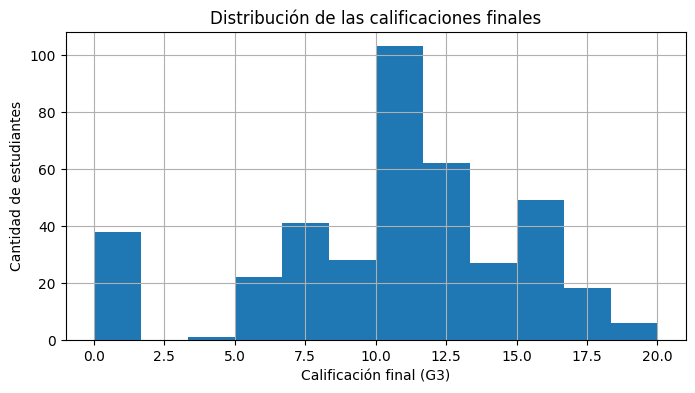

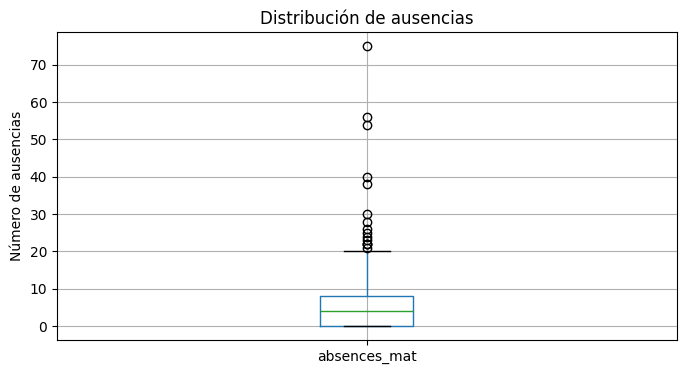

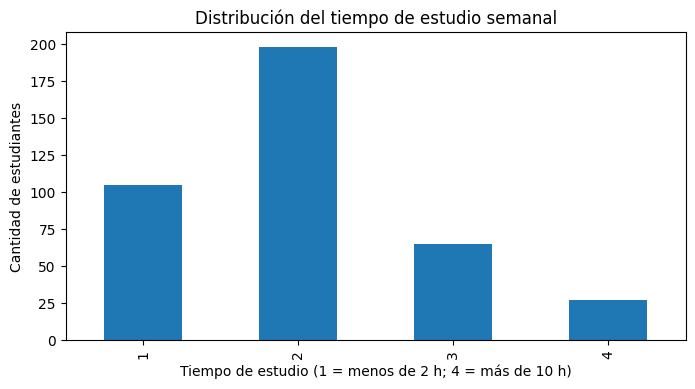

In [7]:
# Gráfica 1: distribución de calificaciones finales
plt.figure(figsize=(8, 4))
datos["G3_mat"].hist(bins=12)
plt.title("Distribución de las calificaciones finales")
plt.xlabel("Calificación final (G3)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

# Gráfica 2: valores atípicos de ausencias
plt.figure(figsize=(8, 4))
datos.boxplot(column="absences_mat")
plt.title("Distribución de ausencias")
plt.ylabel("Número de ausencias")
plt.show()

# Gráfica 3: frecuencia del tiempo de estudio
plt.figure(figsize=(8, 4))
datos["studytime_mat"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución del tiempo de estudio semanal")
plt.xlabel("Tiempo de estudio (1 = menos de 2 h; 4 = más de 10 h)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

### Hallazgos del análisis exploratorio

La siguiente celda genera cinco hallazgos con cifras calculadas desde la muestra completa de Matemáticas. Al interpretar, conserva las cifras que aparezcan después de ejecutar el notebook. Las diferencias son descriptivas y no demuestran causalidad.

In [8]:
# Hallazgo 1: rendimiento general y proporción de bajo rendimiento
promedio_g3 = datos["G3_mat"].mean()
mediana_g3 = datos["G3_mat"].median()
porcentaje_bajo = y.mean() * 100
print(
    f"1. Rendimiento general: la media de G3 es {promedio_g3:.2f}/20 y "
    f"la mediana es {mediana_g3:.2f}/20. El {porcentaje_bajo:.1f}% de los "
    "estudiantes presenta bajo rendimiento (G3 < 10). Esto permite dimensionar "
    "la proporción que podría requerir seguimiento."
)

# Hallazgo 2: tiempo de estudio
promedios_estudio = datos.groupby("studytime_mat")["G3_mat"].mean().sort_index()
conteos_estudio = datos["studytime_mat"].value_counts().sort_index()
if len(promedios_estudio) >= 2:
    nivel_mayor = int(promedios_estudio.idxmax())
    nivel_menor = int(promedios_estudio.idxmin())
    print(
        f"2. Tiempo de estudio: el promedio más alto de G3 aparece en la categoría "
        f"{nivel_mayor} ({promedios_estudio.max():.2f}; n={conteos_estudio[nivel_mayor]}), "
        f"y el más bajo en la categoría {nivel_menor} ({promedios_estudio.min():.2f}; "
        f"n={conteos_estudio[nivel_menor]}). La diferencia sugiere una asociación "
        "que merece seguimiento, pero no prueba que estudiar más cause una nota mayor."
    )

# Hallazgo 3: reprobaciones previas
sin_reprobaciones = datos.loc[datos["failures_mat"] == 0, "G3_mat"]
con_reprobaciones = datos.loc[datos["failures_mat"] > 0, "G3_mat"]
if len(sin_reprobaciones) and len(con_reprobaciones):
    print(
        f"3. Reprobaciones previas: el promedio de G3 es {sin_reprobaciones.mean():.2f} "
        f"sin reprobaciones previas (n={len(sin_reprobaciones)}) y "
        f"{con_reprobaciones.mean():.2f} con al menos una reprobación (n={len(con_reprobaciones)}). "
        "El antecedente de reprobación puede ser una señal útil para priorizar acompañamiento."
    )

# Hallazgo 4: ausencias y calificación final
correlacion_ausencias = datos["absences_mat"].corr(datos["G3_mat"])
print(
    f"4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es "
    f"{correlacion_ausencias:.3f}. Este valor describe la intensidad y dirección de la "
    "asociación lineal en la muestra; por sí solo no permite concluir causalidad."
)

# Hallazgo 5: apoyo escolar extra
if "schoolsup_mat" in datos.columns:
    tabla_apoyo = datos.assign(bajo_rendimiento=y).groupby("schoolsup_mat").agg(
        estudiantes=("G3_mat", "size"),
        promedio_G3=("G3_mat", "mean"),
        porcentaje_bajo=("bajo_rendimiento", lambda s: s.mean() * 100)
    )
    print("5. Apoyo escolar adicional: promedio final y porcentaje de bajo rendimiento por grupo (yes/no).")
    display(tabla_apoyo.round(2))
    print("La tabla permite comparar descriptivamente los grupos; el apoyo no debe interpretarse como causa del resultado, porque puede ofrecerse precisamente a estudiantes que ya presentan dificultades.")

1. Rendimiento general: la media de G3 es 10.42/20 y la mediana es 11.00/20. El 32.9% de los estudiantes presenta bajo rendimiento (G3 < 10). Esto permite dimensionar la proporción que podría requerir seguimiento.
2. Tiempo de estudio: el promedio más alto de G3 aparece en la categoría 3 (11.40; n=65), y el más bajo en la categoría 1 (10.05; n=105). La diferencia sugiere una asociación que merece seguimiento, pero no prueba que estudiar más cause una nota mayor.
3. Reprobaciones previas: el promedio de G3 es 11.25 sin reprobaciones previas (n=312) y 7.27 con al menos una reprobación (n=83). El antecedente de reprobación puede ser una señal útil para priorizar acompañamiento.
4. Ausencias y calificación: la correlación de Pearson entre ausencias y G3 es 0.034. Este valor describe la intensidad y dirección de la asociación lineal en la muestra; por sí solo no permite concluir causalidad.
5. Apoyo escolar adicional: promedio final y porcentaje de bajo rendimiento por grupo (yes/no).


,estudiantes,promedio_G3,porcentaje_bajo
schoolsup_mat,,,
no,344,10.56,31.1
yes,51,9.43,45.1


La tabla permite comparar descriptivamente los grupos; el apoyo no debe interpretarse como causa del resultado, porque puede ofrecerse precisamente a estudiantes que ya presentan dificultades.


Ingeniería de características y pipeline  4

Se crean tres variables derivadas con sentido para el seguimiento académico:

1. `grade_progress_mat`: diferencia entre la segunda y la primera evaluación (`G2 - G1`). Solo es un predictor válido si el seguimiento se realiza después de conocer G2.
2. `has_failures_mat`: indicador de al menos una reprobación previa.
3. `absence_level_mat`: clasificación de ausencias en cuatro niveles.

La función codifica todas las columnas categóricas y escala las ausencias con Min-Max. Las marcas de atípicos se conservan en la base de calidad, pero se excluyen de las variables predictoras. La nota final `G3_mat` se mantiene en la tabla transformada para construir el objetivo, pero se elimina de `X` para evitar fuga de información.

In [9]:
def preparar_features(data):
    """Deriva variables, codifica categorías y escala ausencias de forma reproducible."""
    data = data.copy()

    # 1. Progreso académico entre la primera y segunda evaluación
    data["grade_progress_mat"] = data["G2_mat"] - data["G1_mat"]

    # 2. Indicador de al menos una reprobación previa
    data["has_failures_mat"] = (data["failures_mat"] > 0).astype(int)

    # 3. Clasificación del nivel de ausencias
    data["absence_level_mat"] = pd.cut(
        data["absences_mat"],
        bins=[-1, 0, 5, 15, float("inf")],
        labels=["Sin ausencias", "Bajas", "Medias", "Altas"]
    )

    # Evitar que los indicadores de revisión de calidad entren al modelo
    data = data.drop(
        columns=["marca_atipico_ausencias", "marca_atipico_G3"],
        errors="ignore"
    )

    # Codificar todas las variables categóricas
    columnas_categoricas = data.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    if columnas_categoricas:
        data = pd.get_dummies(
            data,
            columns=columnas_categoricas,
            dtype=int
        )

    # Escalado Min-Max de ausencias
    minimo = data["absences_mat"].min()
    maximo = data["absences_mat"].max()
    if maximo != minimo:
        data["absences_scaled"] = (
            (data["absences_mat"] - minimo) / (maximo - minimo)
        )
    else:
        data["absences_scaled"] = 0.0

    return data

# Ejecutar el pipeline
UMBRAL_BAJO_RENDIMIENTO = 10
df_features = preparar_features(datos)
print("Dimensiones de la base transformada:", df_features.shape)
display(df_features.head())

# Verificar que no queden columnas object/category sin codificar
columnas_categoricas_pendientes = df_features.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print("Columnas categóricas pendientes:", columnas_categoricas_pendientes)

# Comprobar reproducibilidad
# Dos ejecuciones sobre la misma entrada deben producir exactamente la misma salida.
df_v1 = preparar_features(datos)
df_v2 = preparar_features(datos)
print("¿El pipeline es reproducible?", df_v1.equals(df_v2))

Dimensiones de la base transformada: (395, 66)


,age_mat,Medu_mat,Fedu_mat,traveltime_mat,studytime_mat,failures_mat,famrel_mat,freetime_mat,goout_mat,Dalc_mat,...,higher_mat_yes,internet_mat_no,internet_mat_yes,romantic_mat_no,romantic_mat_yes,absence_level_mat_Sin ausencias,absence_level_mat_Bajas,absence_level_mat_Medias,absence_level_mat_Altas,absences_scaled
0,18,4,4,2,2,0,4,3,4,1,...,1,1,0,1,0,0,0,1,0,0.080000
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,1,0,0,1,0,0,0.053333
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,1,0,0,0,1,0,0.133333
3,15,4,2,1,3,0,3,2,2,1,...,1,0,1,0,1,0,1,0,0,0.026667
4,16,3,3,1,2,0,4,3,2,1,...,1,1,0,1,0,0,1,0,0,0.053333


Columnas categóricas pendientes: []
¿El pipeline es reproducible? True


### Preparación de la variable objetivo y predictores

Se define `y = 1` cuando `G3_mat < 10` y `y = 0` cuando `G3_mat >= 10`. La calificación final `G3_mat` se excluye de `X` porque es el resultado que se desea identificar.

**Alcance temporal:** como la variable `grade_progress_mat` utiliza G1 y G2, este conjunto de predictores representa una alerta que se realiza después de la segunda evaluación. Si se necesitara una alerta antes de conocer G2, habría que retirar G1, G2 y `grade_progress_mat` de los predictores.

In [10]:
y = (datos["G3_mat"] < UMBRAL_BAJO_RENDIMIENTO).astype(int).rename("bajo_rendimiento")
X = df_features.drop(columns=["G3_mat"], errors="ignore")

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):")
display(y.value_counts().sort_index().rename(index={0: "Aprobación", 1: "Bajo rendimiento"}))

# Comprobación explícita de que G3 no está en los predictores
print("¿G3_mat está dentro de X?", "G3_mat" in X.columns)

Dimensiones de X: (395, 65)
Dimensiones de y: (395,)
Distribución del objetivo (0 = G3 >= 10; 1 = G3 < 10):


,count
bajo_rendimiento,
Aprobación,265
Bajo rendimiento,130


¿G3_mat está dentro de X? False


 Segmentación de estudiantes – análisis preliminar

Se aplica K-means sobre variables disponibles antes del cierre del periodo: edad, tiempo de estudio, reprobaciones previas, ausencias y calificaciones de los dos primeros periodos (G1 y G2). La calificación final (G3_mat) no participa en el entrenamiento de los grupos; se utiliza únicamente después para describir los segmentos.

Las variables se estandarizan antes de aplicar K-means. Se comparan soluciones de 2 a 5 grupos mediante el coeficiente silhouette. La selección es exploratoria: también deben considerarse la separación de los grupos, su interpretación y las indicaciones del profesor.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

columnas_segmentacion = [
    "age_mat", "studytime_mat", "failures_mat",
    "absences_mat", "G1_mat", "G2_mat"
]

X_segmentacion = datos[columnas_segmentacion].copy()
escalador_segmentacion = StandardScaler()
X_segmentacion_escalado = escalador_segmentacion.fit_transform(X_segmentacion)

# Comparar soluciones de 2 a 5 grupos mediante silhouette.
resultados_k = []
for k in range(2, 6):
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo_k.fit_predict(X_segmentacion_escalado)
    resultados_k.append({
        "k": k,
        "inercia": modelo_k.inertia_,
        "silhouette": silhouette_score(X_segmentacion_escalado, etiquetas_k)
    })

comparacion_k = pd.DataFrame(resultados_k).sort_values("silhouette", ascending=False)
print("Comparación preliminar del número de grupos:")
display(comparacion_k.round(3))

mejor_k = int(comparacion_k.iloc[0]["k"])
modelo_segmentacion = KMeans(n_clusters=mejor_k, random_state=42, n_init=10)
clusters = modelo_segmentacion.fit_predict(X_segmentacion_escalado)

resultado_segmentacion = datos.copy()
resultado_segmentacion["cluster"] = clusters
resultado_segmentacion["bajo_rendimiento"] = y.values

resumen_clusters = resultado_segmentacion.groupby("cluster").agg(
    estudiantes=("G3_mat", "size"),
    promedio_G3=("G3_mat", "mean"),
    promedio_ausencias=("absences_mat", "mean"),
    promedio_tiempo_estudio=("studytime_mat", "mean"),
    promedio_reprobaciones=("failures_mat", "mean"),
    porcentaje_bajo_rendimiento=("bajo_rendimiento", lambda s: s.mean() * 100)
).round(2)

print(f"Número de grupos seleccionado preliminarmente: {mejor_k}")
print("Perfil descriptivo de los segmentos:")
display(resumen_clusters)

print("La interpretación descriptiva de cada cluster aparece en la siguiente sección. Los grupos son preliminares y deben validarse con las indicaciones del profesor.")

Comparación preliminar del número de grupos:


,k,inercia,silhouette
3,5,1176.568,0.223
2,4,1336.343,0.222
0,2,1817.295,0.220
1,3,1535.986,0.205


Número de grupos seleccionado preliminarmente: 5
Perfil descriptivo de los segmentos:


,estudiantes,promedio_G3,promedio_ausencias,promedio_tiempo_estudio,promedio_reprobaciones,porcentaje_bajo_rendimiento
cluster,,,,,,
0,47,10.53,21.02,1.81,0.43,38.30
1,78,12.29,3.96,3.35,0.06,17.95
2,127,7.32,3.43,1.80,0.17,56.69
3,112,13.94,3.20,1.62,0.07,0.00
4,31,5.45,5.29,1.58,2.52,83.87


La interpretación descriptiva de cada cluster aparece en la siguiente sección. Los grupos son preliminares y deben validarse con las indicaciones del profesor.


### Interpretación descriptiva de los segmentos

El algoritmo K-means permitió identificar cinco grupos preliminares de estudiantes con características académicas diferentes.

Según el perfil calculado para esta ejecución:

- **Cluster 0 (47 estudiantes):** presenta el promedio más alto de ausencias (21,02) y un 38,30 % de bajo rendimiento. Se caracteriza principalmente por ausentismo elevado.
- **Cluster 1 (78 estudiantes):** tiene el mayor tiempo de estudio promedio (3,35), una nota final promedio de 12,29 y un 17,95 % de bajo rendimiento.
- **Cluster 2 (127 estudiantes):** tiene una nota final promedio de 7,32 y un 56,69 % de bajo rendimiento; es un grupo numeroso con dificultades académicas frecuentes.
- **Cluster 3 (112 estudiantes):** registra la nota final promedio más alta (13,94) y 0 % de bajo rendimiento según el umbral usado en este ejercicio.
- **Cluster 4 (31 estudiantes):** presenta la nota final promedio más baja (5,45), el promedio más alto de reprobaciones previas (2,52) y un 83,87 % de bajo rendimiento. Es el grupo que requiere mayor atención en esta segmentación.

Los números de cluster son etiquetas técnicas asignadas por K-means y no representan un orden. Los perfiles describen asociaciones dentro de esta muestra; no demuestran causas. La elección final de K debe validarse con las instrucciones de la sesión en vivo.

Conclusión de la segmentación:

Logramos diferenciar perfiles según sus notas, ausencias y reprobaciones previas. En particular, los grupos 2 y 4 concentran la mayor cantidad de estudiantes con bajo rendimiento, así que son los candidatos directos para priorizar tutorías y acompañamiento.

Eso sí, este ejercicio es puramente exploratorio y no implica causalidad. A nivel técnico, el mejor coeficiente de Silhouette fue de apenas 0,223 (con 5 grupos), prácticamente empatado con el 0,222 de 4 grupos. Esto nos dice que los clústeres están bastante solapados y poco definidos, por lo que elegir 5 grupos es solo una propuesta preliminar que conviene revisar en clase.